<a href="https://colab.research.google.com/github/esrakonya/osmanlica-koken-tahmini/blob/main/osmanlica_koken_projesi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Osmanlıca kelime köken tahmini
Arap harfli yazılmış Osmanlıca bir kelimenin köken dilini (Arapça / Farsça / Türkçe) yalnızca yazımından tahmin etme.

**Veri:** Vikisözlük (en.wiktionary.org), CC BY-SA 4.0 ve GFDL. **Bölümler:** A veri toplama (isteğe bağlı) → B bölme ve inceleme → C keşif → D model seçimi (doğrulama) → E nihai test ve ek analizler.

**Çalıştırma:** Tümünü çalıştırabilirsin. Önce `osmanlica_koken.csv` dosyasını Colab'a yükle. **Test kümesi yalnızca E bölümünde kullanılır.**

## Ayar

In [2]:
import os
# Veri toplama (Vikisözlük API) yalnızca sıfırdan üretmek istersen True yap.
# False iken osmanlica_koken.csv dosyasını Colab'a yüklemen yeterli (önerilen; sonuçlar aynı veriyle tekrarlanır).
VERI_TOPLA = False
if not VERI_TOPLA and not os.path.exists("osmanlica_koken.csv"):
    print("UYARI: osmanlica_koken.csv bulunamadı. Dosyayı yükle veya VERI_TOPLA = True yap.")

## A. Veri toplama (isteğe bağlı, `VERI_TOPLA = True` gerekir)

### Köken kategorilerini listele

In [3]:
if VERI_TOPLA:
    import requests, time, re, collections
    import pandas as pd

    API = "https://en.wiktionary.org/w/api.php"
    HEADERS = {"User-Agent": "OsmanliKokenProjesi/1.0 (ogrenci ders projesi)"}

    def api_get(params):
        params = {**params, "format": "json"}
        r = requests.get(API, params=params, headers=HEADERS, timeout=30)
        r.raise_for_status()
        return r.json()

    # "Ottoman Turkish terms ..." ile başlayan tüm kategorileri listele
    cats, cont = [], {}
    while True:
        d = api_get({"action": "query", "list": "allcategories",
                     "acprefix": "Ottoman Turkish terms", "aclimit": 500, **cont})
        cats += [c["*"] for c in d["query"]["allcategories"]]
        if "continue" not in d: break
        cont = d["continue"]
        time.sleep(0.3)

    for c in cats:
        if re.search(r"(borrowed|inherited) from", c):
            print(c)

### Kategorilerden kelime ve etiket toplama (önbellekli)

In [4]:
if VERI_TOPLA:
    import requests, time, re, json, os
    import pandas as pd

    API = "https://en.wiktionary.org/w/api.php"
    session = requests.Session()
    session.headers.update({"User-Agent": "OsmanliKokenProjesi/1.0 (ogrenci ders projesi)"})

    def api_get(params, max_retry=8):
        params = {**params, "format": "json", "maxlag": 5}
        for attempt in range(max_retry):
            r = session.get(API, params=params, timeout=60)
            if r.status_code == 429 or r.status_code >= 500:
                try:
                    wait = int(r.headers.get("Retry-After", ""))
                except ValueError:
                    wait = min(60, 2 ** attempt * 2)
                print(f"  HTTP {r.status_code}, {wait} sn bekleniyor...")
                time.sleep(wait)
                continue
            r.raise_for_status()
            d = r.json()
            if d.get("error", {}).get("code") == "maxlag":
                time.sleep(5)
                continue
            return d
        raise RuntimeError("Çok fazla deneme yapıldı, birkaç dakika sonra tekrar çalıştır.")

    def category_members(title):
        fn = "cache_" + re.sub(r"\W+", "_", title) + ".json"
        if os.path.exists(fn):
            with open(fn, encoding="utf-8") as f:
                return json.load(f)
        members, cont = [], {}
        while True:
            d = api_get({"action": "query", "list": "categorymembers",
                         "cmtitle": title, "cmlimit": 500, "cmnamespace": 0, **cont})
            members += [m["title"] for m in d["query"]["categorymembers"]]
            if "continue" not in d:
                break
            cont = d["continue"]
            time.sleep(1.0)
        with open(fn, "w", encoding="utf-8") as f:
            json.dump(members, f, ensure_ascii=False)
        return members

    PREFIX = "Category:Ottoman Turkish terms "
    LABEL_CATS = {
        "Arapça": ["borrowed from Arabic"],
        "Farsça": ["borrowed from Persian",
                   "borrowed from Classical Persian",
                   "borrowed from Iranian Persian",
                   "borrowed from Dari"],
        "Türkçe": ["inherited from Proto-Turkic",
                   "inherited from Proto-Common Turkic",
                   "inherited from Proto-Oghuz",
                   "inherited from Early Old Oghuz"],
    }

    rows = []
    for label, suffixes in LABEL_CATS.items():
        for s in suffixes:
            words = category_members(PREFIX + s)
            print(f"{label:7} | {s:38} | {len(words)} madde")
            if len(words) == 0:
                print("   UYARI: kategori boş veya adı farklı olabilir")
            rows += [(w, label) for w in words]
    df_raw = pd.DataFrame(rows, columns=["kelime", "sinif"])

    lemmas = set(category_members("Category:Ottoman Turkish lemmas"))
    print("Toplam Osmanlıca lemma:", len(lemmas))

### Temizlik ve CSV üretimi

In [5]:
if VERI_TOPLA:
    ARAP_HARF = re.compile(r"^[\u0621-\u063A\u0641-\u064A\u066E-\u06D3\u0670\u200c]+$")
    HAREKE = re.compile(r"[\u064B-\u065F\u0670]")

    df = df_raw.copy()
    df = df[df["kelime"].isin(lemmas)]                 # sadece ana sözcükler
    df["kelime"] = df["kelime"].str.replace(HAREKE, "", regex=True)
    df = df[df["kelime"].str.match(ARAP_HARF)]         # tek kelime, sadece Arap harfi
    df = df.drop_duplicates()

    # Birden fazla sınıfta görünenler (çakışma) ayrıca incelensin
    n_sinif = df.groupby("kelime")["sinif"].nunique()
    cakisan = n_sinif[n_sinif > 1].index
    print("Çakışan kelime sayısı:", len(cakisan))

    df = df[~df["kelime"].isin(cakisan)].reset_index(drop=True)
    print(df["sinif"].value_counts())
    print("Toplam:", len(df))

    df.to_csv("osmanlica_koken.csv", index=False)
    display(df.sample(10, random_state=1))

### CSV'yi indir

In [6]:
if VERI_TOPLA:
    from google.colab import files
    files.download("osmanlica_koken.csv")

## B. Son temizlik, bölme ve ham veri incelemesi
**Girdi:** `osmanlica_koken.csv` → **Çıktı:** `train.csv`, `val.csv`, `test.csv` (70/15/15, stratified, `random_state=42`)

### Son temizlik ve stratified bölme

In [7]:
# ============================================================
# train.csv / val.csv / test.csv dosyalarını osmanlica_koken.csv'den YENİDEN ÜRETİR.
# Not defterindeki 8. hücrenin (bölme hücresi) adımlarının aynısıdır; random_state=42.
# Önce osmanlica_koken.csv dosyasını Colab'a yükle (sol panel -> Dosyalar -> yükle).
# Ağ gerekir: sadece "Ottoman Turkish proper nouns" kategorisi çekilir (özel isim bayrağı için).
# ============================================================
import re, os, json, time, requests, pandas as pd
from sklearn.model_selection import train_test_split

API = "https://en.wiktionary.org/w/api.php"
session = requests.Session()
session.headers.update({"User-Agent": "OsmanliKokenProjesi/1.0 (ogrenci ders projesi)"})

def api_get(params, max_retry=8):
    params = {**params, "format": "json", "maxlag": 5}
    for attempt in range(max_retry):
        r = session.get(API, params=params, timeout=60)
        if r.status_code == 429 or r.status_code >= 500:
            try:
                wait = int(r.headers.get("Retry-After", ""))
            except ValueError:
                wait = min(60, 2 ** attempt * 2)
            print(f"  HTTP {r.status_code}, {wait} sn bekleniyor...")
            time.sleep(wait); continue
        r.raise_for_status()
        d = r.json()
        if d.get("error", {}).get("code") == "maxlag":
            time.sleep(5); continue
        return d
    raise RuntimeError("Çok fazla deneme yapıldı, birkaç dakika sonra tekrar çalıştır.")

def category_members(title):
    fn = "cache_" + re.sub(r"\W+", "_", title) + ".json"
    if os.path.exists(fn):
        with open(fn, encoding="utf-8") as f:
            return json.load(f)
    members, cont = [], {}
    while True:
        d = api_get({"action": "query", "list": "categorymembers",
                     "cmtitle": title, "cmlimit": 500, "cmnamespace": 0, **cont})
        members += [m["title"] for m in d["query"]["categorymembers"]]
        if "continue" not in d:
            break
        cont = d["continue"]; time.sleep(1.0)
    with open(fn, "w", encoding="utf-8") as f:
        json.dump(members, f, ensure_ascii=False)
    return members

HAREKE = re.compile(r"[\u064B-\u065F\u0670]")
df = pd.read_csv("osmanlica_koken.csv")
print("Okunan satır:", len(df), "(not defterinde bu dosya 3302 satırdı)")

df = df[df["kelime"].str.len() >= 2].copy()                       # 1) alfabe maddeleri
df["kelime"] = df["kelime"].str.replace("\u200c", "", regex=False)  # 2) ZWNJ
ozel = {HAREKE.sub("", w).replace("\u200c", "")
        for w in category_members("Category:Ottoman Turkish proper nouns")}
df["ozel_isim"] = df["kelime"].isin(ozel)                          # 3) özel isim bayrağı
df = df.drop_duplicates(["kelime", "sinif"])                       # 4) yineleme / çakışma
cakisan = df.groupby("kelime")["sinif"].nunique()
df = df[~df["kelime"].isin(cakisan[cakisan > 1].index)].reset_index(drop=True)
print("Temiz veri:", len(df), "(beklenen 3298)"); print(df["sinif"].value_counts().to_dict())

train, temp = train_test_split(df, test_size=0.30, stratify=df["sinif"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["sinif"], random_state=42)
for ad, d in [("train", train), ("val", val), ("test", test)]:
    d.to_csv(f"{ad}.csv", index=False)
    print(ad, len(d), d["sinif"].value_counts(normalize=True).round(3).to_dict())
print("\nBeklenen: train 2308 / val 495 / test 495 ve Türkçe 1089, Arapça 1466, Farsça 743.")

Okunan satır: 3302 (not defterinde bu dosya 3302 satırdı)
Temiz veri: 3298 (beklenen 3298)
{'Arapça': 1466, 'Türkçe': 1089, 'Farsça': 743}
train 2308 {'Arapça': 0.445, 'Türkçe': 0.33, 'Farsça': 0.225}
val 495 {'Arapça': 0.444, 'Türkçe': 0.331, 'Farsça': 0.224}
test 495 {'Arapça': 0.444, 'Türkçe': 0.329, 'Farsça': 0.226}

Beklenen: train 2308 / val 495 / test 495 ve Türkçe 1089, Arapça 1466, Farsça 743.


In [8]:
import pandas as pd

df = pd.read_csv("osmanlica_koken.csv")
print("Eksik değer sayısı:")
print(df.isna().sum())
print("\nBoş (sadece boşluk) kelime sayısı:", (df["kelime"].str.strip() == "").sum())

Eksik değer sayısı:
kelime    0
sinif     0
dtype: int64

Boş (sadece boşluk) kelime sayısı: 0


### Ham veri incelemesi 1: şüpheli uzunluklar, harf envanteri, referanslar

In [9]:
import pandas as pd, collections
df = pd.read_csv("osmanlica_koken.csv")
df["uzunluk"] = df["kelime"].str.len()

# 1) Şüpheli uzunluklar
print("1 harfli kelimeler:")
print(df[df.uzunluk <= 1].to_string())
print("\n9+ harfli örnekler:")
print(df[df.uzunluk >= 9].groupby("sinif").head(4).to_string())

# 2) Harf envanteri: sadece tek sınıfta görülen harfler (sızıntı kontrolü)
siniflar = list(df.sinif.unique())
sayac = {k: collections.Counter("".join(df[df.sinif == k]["kelime"])) for k in siniflar}
rows = [{"harf": ch, "kod": f"U+{ord(ch):04X}", **{k: sayac[k][ch] for k in siniflar}}
        for ch in sorted(set().union(*[set(c) for c in sayac.values()]))]
inv = pd.DataFrame(rows)
print("\nToplam farklı harf:", len(inv))
print("Sadece tek sınıfta görülen harfler:")
print(inv[(inv[siniflar] > 0).sum(axis=1) == 1].to_string())

# 3) Basit referans değerleri
print("\nÇoğunluk sınıfı doğruluğu:", round(df.sinif.value_counts(normalize=True).max(), 3))
kural = df["kelime"].str.endswith(("مك", "مق"))
turkce = df.sinif == "Türkçe"
print("Mastar kuralı: precision =", round((kural & turkce).sum() / kural.sum(), 3),
      "| Türkçe recall =", round((kural & turkce).sum() / turkce.sum(), 3))

1 harfli kelimeler:
     kelime   sinif  uzunluk
0         ء  Arapça        1
1025      ك  Arapça        1
1818      گ  Farsça        1
1819      ی  Farsça        1

9+ harfli örnekler:
          kelime   sinif  uzunluk
987    قسطنطینیه  Arapça        9
1103   ماشاءالله  Arapça        9
1606  سلسله‌نامه  Farsça       10
1654   فرماننامه  Farsça        9
1833   آذربایجان  Farsça        9
1862   افغانستان  Farsça        9
2302   اسیركه‌مك  Türkçe        9

Toplam farklı harf: 39
Sadece tek sınıfta görülen harfler:
   harf     kod  Arapça  Farsça  Türkçe
0     ء  U+0621       7       0       0
2     أ  U+0623       8       0       0
3     ؤ  U+0624       5       0       0
7     ة  U+0629       1       0       0
22    ظ  U+0638      28       0       0
35    ژ  U+0698       0       4       0
36    گ  U+06AF       0       1       0

Çoğunluk sınıfı doğruluğu: 0.445
Mastar kuralı: precision = 0.989 | Türkçe recall = 0.24


### Ham veri incelemesi 2: 1 harfli kayıtlar, ZWNJ, özel isimler, son harf tablosu

In [10]:
import re, pandas as pd

df = pd.read_csv("osmanlica_koken.csv")
HAREKE = re.compile(r"[\u064B-\u065F\u0670]")

# 1) Alfabe maddelerini (1 harfli kayıtlar) çıkar
df = df[df["kelime"].str.len() >= 2].reset_index(drop=True)
print("1 harfli kayıtlar çıkarıldıktan sonra:", len(df))

# 2) ZWNJ dağılımı
df["zwnj"] = df["kelime"].str.contains("\u200c")
print("\nZWNJ içeren kelimeler:")
print(df.groupby("sinif")["zwnj"].agg(["sum", "mean"]).round(4))
print(df[df.zwnj].groupby("sinif").head(5)[["kelime", "sinif"]].to_string())

# 3) Özel isimler
ozel = {HAREKE.sub("", w) for w in category_members("Category:Ottoman Turkish proper nouns")}
df["ozel_isim"] = df["kelime"].isin(ozel)
print("\nÖzel isimler:")
print(df.groupby("sinif")["ozel_isim"].agg(["sum", "mean"]).round(4))
print(df[df.ozel_isim].groupby("sinif").head(6)[["kelime", "sinif"]].to_string())

# 4) Son harf tablosu (Grafik 3'ün sayısal karşılığı)
son = pd.crosstab(df["kelime"].str[-1], df["sinif"], normalize="columns").round(3)
son["maks_fark"] = son.max(axis=1) - son.min(axis=1)
print("\nSon harf oranları (sınıflar arası farkı en büyük 12 harf):")
print(son.sort_values("maks_fark", ascending=False).head(12))

1 harfli kayıtlar çıkarıldıktan sonra: 3298

ZWNJ içeren kelimeler:
        sum    mean
sinif              
Arapça    1  0.0007
Farsça    8  0.0108
Türkçe   12  0.0110
          kelime   sinif
1250    مع‌الاسف  Arapça
1604  سلسله‌نامه  Farsça
1609       سه‌پا  Farsça
1895      بی‌نام  Farsça
1914   توران‌دخت  Farsça
1949   خزینه‌دار  Farsça
2298   اسیركه‌مك  Türkçe
2332     اوده‌مك  Türkçe
2347     اوره‌مك  Türkçe
2502     بكزه‌مك  Türkçe
2565     بیله‌مك  Türkçe

Özel isimler:
        sum    mean
sinif              
Arapça  134  0.0914
Farsça   80  0.1077
Türkçe   27  0.0248
      kelime   sinif
3      آخلاط  Arapça
40     ادریس  Arapça
41      ادهم  Arapça
51     ارمیا  Arapça
62     اسحاق  Arapça
63       اسد  Arapça
1468   اروند  Farsça
1471    استا  Farsça
1533  خراسان  Farsça
1534     خرم  Farsça
1537    خندق  Farsça
1542    خیوه  Farsça
2241    آغری  Türkçe
2259     آلپ  Türkçe
2276   آیدین  Türkçe
2287    اردو  Türkçe
2442  ایلغین  Türkçe
2466    باجی  Türkçe

Son harf oranları

## C. Veri keşfi (yalnızca `train.csv`)

### Grafikler için bir kez kurulum

In [11]:
!pip -q install arabic-reshaper python-bidi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 3.1 MB/s eta 0:00:00


### Keşif grafikleri ve oranlar

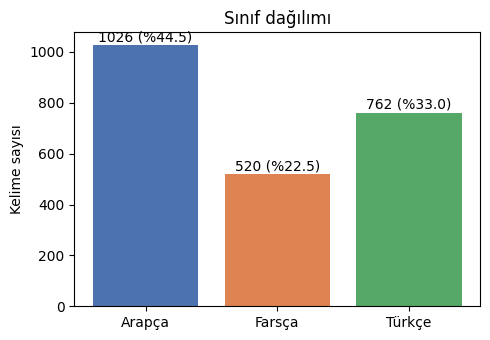

         count  mean   std  min  25%  50%  75%  max
sinif                                              
Arapça  1026.0  4.32  1.02  2.0  4.0  4.0  5.0  9.0
Farsça   520.0  4.63  1.34  2.0  4.0  4.0  5.0  9.0
Türkçe   762.0  4.52  1.21  2.0  4.0  5.0  5.0  8.0


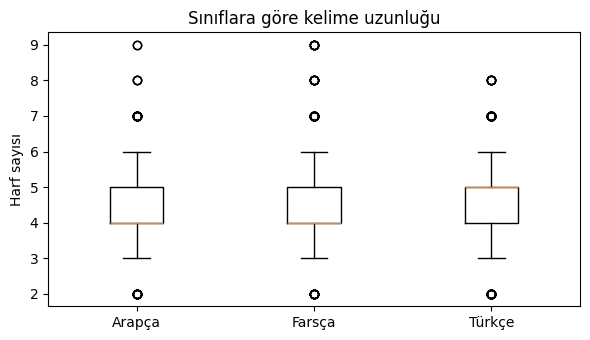

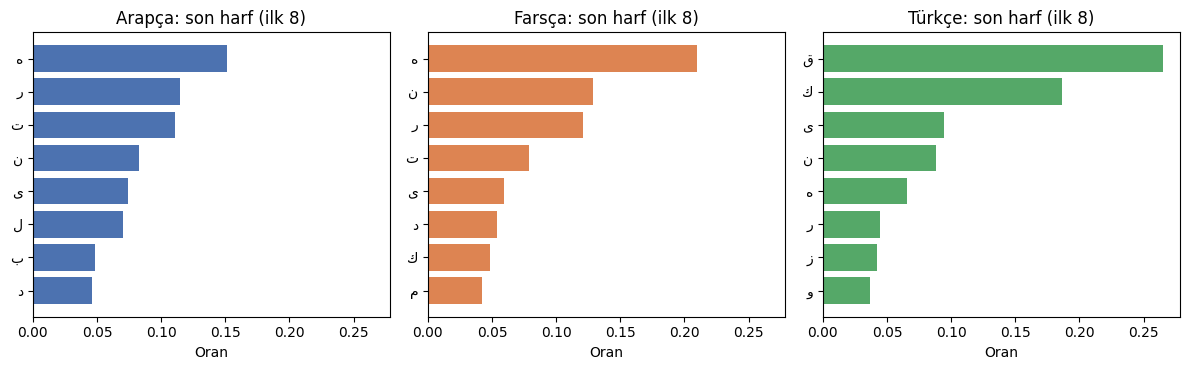


Mastar eki (-مك/-مق) ile bitenlerin oranı:
sinif
Arapça    0.001
Farsça    0.004
Türkçe    0.243
Name: mastar_eki, dtype: float64

'ال' ile başlayanların oranı:
sinif
Arapça    0.008
Farsça    0.004
Türkçe    0.005
Name: al_oneki, dtype: float64

Yazım varyantı harflerinin kelime başına oranı:
        ي (Arapça ye)  ی (Farsça ye)  ك (Arapça kef)  ک (Farsça kef)  \
sinif                                                                  
Arapça            0.0          0.305           0.097             0.0   
Farsça            0.0          0.256           0.223             0.0   
Türkçe            0.0          0.383           0.294             0.0   

        ة (te marbuta)  
sinif                   
Arapça           0.001  
Farsça           0.000  
Türkçe           0.000  
sinif
Arapça    0.036
Farsça    0.058
Türkçe    0.451
Name: kelime, dtype: float64


In [12]:
# ============================================================
# VERİ KEŞFİ - eğitim kümesi (train.csv) üzerinde; val/test kullanılmaz
# ============================================================
# Colab için önce bir kez: !pip -q install arabic-reshaper python-bidi
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display

df = pd.read_csv("train.csv")   # keşif yalnızca eğitim kümesi üzerinde
order = ["Arapça", "Farsça", "Türkçe"]
renk = {"Arapça": "#4C72B0", "Farsça": "#DD8452", "Türkçe": "#55A868"}
ar = lambda s: get_display(arabic_reshaper.reshape(s))

# --- Grafik 1: sınıf dağılımı
sayim = df["sinif"].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(sayim.index, sayim.values, color=[renk[k] for k in sayim.index])
for i, v in enumerate(sayim.values):
    ax.text(i, v + 15, f"{v} (%{100*v/len(df):.1f})", ha="center")
ax.set_ylabel("Kelime sayısı"); ax.set_title("Sınıf dağılımı")
plt.tight_layout(); plt.savefig("g1_sinif.png", dpi=200); plt.show()

# --- Grafik 2: kelime uzunluğu
df["uzunluk"] = df["kelime"].str.len()
print(df.groupby("sinif")["uzunluk"].describe().round(2))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([df[df.sinif == k]["uzunluk"] for k in order]); ax.set_xticklabels(order)
ax.set_ylabel("Harf sayısı"); ax.set_title("Sınıflara göre kelime uzunluğu")
plt.tight_layout(); plt.savefig("g2_uzunluk.png", dpi=200); plt.show()

# --- Grafik 3: kelimenin son harfi
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True)
for ax, k in zip(axes, order):
    son = df[df.sinif == k]["kelime"].str[-1].value_counts(normalize=True).head(8)
    ax.barh([ar(c) for c in son.index][::-1], son.values[::-1], color=renk[k])
    ax.set_title(f"{k}: son harf (ilk 8)")
    ax.set_xlabel("Oran")
plt.tight_layout(); plt.savefig("g3_son_harf.png", dpi=200); plt.show()

# --- Kestirme ve yazım kontrolleri
df["mastar_eki"] = df["kelime"].str.endswith(("مك", "مق"))
df["al_oneki"] = df["kelime"].str.startswith("ال")
print("\nMastar eki (-مك/-مق) ile bitenlerin oranı:")
print(df.groupby("sinif")["mastar_eki"].mean().round(3))
print("\n'ال' ile başlayanların oranı:")
print(df.groupby("sinif")["al_oneki"].mean().round(3))

print("\nYazım varyantı harflerinin kelime başına oranı:")
varyant = {"ي (Arapça ye)": "ي", "ی (Farsça ye)": "ی",
           "ك (Arapça kef)": "ك", "ک (Farsça kef)": "ک", "ة (te marbuta)": "ة"}
tablo = {ad: df.groupby("sinif")["kelime"].apply(lambda s, h=h: s.str.contains(h).mean())
         for ad, h in varyant.items()}
print(pd.DataFrame(tablo).round(3))
print(df.groupby("sinif")["kelime"].apply(lambda s: s.str[-1].isin(["ق", "ك"]).mean()).round(3))

## D. Model seçimi (yalnızca doğrulama kümesi; test kullanılmaz)

### LR ve SVM ayar taraması

In [13]:
import pandas as pd, numpy as np, itertools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv")
sinif_sirasi = ["Arapça", "Farsça", "Türkçe"]
mark = lambda s: "^" + s + "$"
Xtr, ytr = train["kelime"].map(mark), train["sinif"]
Xva, yva = val["kelime"].map(mark), val["sinif"]

# M0: çoğunluk sınıfı
m0 = ytr.value_counts().idxmax()
print(f"M0 (hep {m0}): acc={accuracy_score(yva, [m0]*len(yva)):.3f} "
      f"macro-F1={f1_score(yva, [m0]*len(yva), average='macro'):.3f}")

# M1 ve M2: hiperparametre taraması (sadece doğrulama kümesi)
sonuclar = []
for ad, ngram, C, cw in itertools.product(
        ["LR", "SVM"], [(1, 3), (1, 4), (2, 4)], [0.3, 1, 3, 10], [None, "balanced"]):
    clf = (LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=42)
           if ad == "LR" else LinearSVC(C=C, class_weight=cw, random_state=42))
    pipe = make_pipeline(TfidfVectorizer(analyzer="char", ngram_range=ngram, sublinear_tf=True), clf)
    pipe.fit(Xtr, ytr)
    p = pipe.predict(Xva)
    sonuclar.append(dict(model=ad, ngram=ngram, C=C, class_weight=cw,
                         acc=accuracy_score(yva, p), macro_f1=f1_score(yva, p, average="macro"),
                         pipe=pipe))
res = pd.DataFrame(sonuclar)
print("\nHer modelin en iyi 3 ayarı (doğrulama macro-F1'e göre):")
for ad in ["LR", "SVM"]:
    print(res[res.model == ad].sort_values("macro_f1", ascending=False)
             .head(3).drop(columns="pipe").round(3).to_string(index=False))

# En iyi LR ve SVM için ayrıntılı rapor
for ad in ["LR", "SVM"]:
    en_iyi = res[res.model == ad].sort_values("macro_f1", ascending=False).iloc[0]
    p = en_iyi["pipe"].predict(Xva)
    print(f"\n=== {ad} (ngram={en_iyi['ngram']}, C={en_iyi['C']}, cw={en_iyi['class_weight']}) ===")
    print(classification_report(yva, p, labels=sinif_sirasi, digits=3))
    print(pd.DataFrame(confusion_matrix(yva, p, labels=sinif_sirasi),
                       index=[f"gerçek:{k}" for k in sinif_sirasi],
                       columns=[f"tahmin:{k}" for k in sinif_sirasi]))

M0 (hep Arapça): acc=0.444 macro-F1=0.205

Her modelin en iyi 3 ayarı (doğrulama macro-F1'e göre):
model  ngram   C class_weight   acc  macro_f1
   LR (1, 3) 1.0     balanced 0.808     0.795
   LR (1, 4) 1.0     balanced 0.802     0.790
   LR (1, 3) 3.0     balanced 0.800     0.783
model  ngram   C class_weight   acc  macro_f1
  SVM (1, 3) 0.3     balanced 0.804     0.785
  SVM (1, 4) 0.3         None 0.806     0.781
  SVM (1, 3) 0.3         None 0.804     0.777

=== LR (ngram=(1, 3), C=1.0, cw=balanced) ===
              precision    recall  f1-score   support

      Arapça      0.864     0.809     0.836       220
      Farsça      0.656     0.739     0.695       111
      Türkçe      0.854     0.854     0.854       164

    accuracy                          0.808       495
   macro avg      0.791     0.800     0.795       495
weighted avg      0.814     0.808     0.810       495

               tahmin:Arapça  tahmin:Farsça  tahmin:Türkçe
gerçek:Arapça            178             26   

### En iyi LR: katsayılar ve doğrulama hata incelemesi

In [14]:
import numpy as np, pandas as pd

en_iyi = res[res.model == "LR"].sort_values("macro_f1", ascending=False).iloc[0]["pipe"]
vect, clf = en_iyi.steps[0][1], en_iyi.steps[1][1]
feats = vect.get_feature_names_out()

print("Her sınıf için en yüksek katsayılı 10 harf dizisi:")
for i, k in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[::-1][:10]
    print(f"{k}: {[feats[j] for j in top]}")

val2 = val.copy()
val2["tahmin"] = en_iyi.predict(Xva)
val2["dogru"] = val2["tahmin"] == val2["sinif"]

print("\nÖzel isim ve diğer kelimelerde doğruluk:")
print(val2.groupby("ozel_isim")["dogru"].agg(["mean", "count"]).round(3))

tr = val2[val2.sinif == "Türkçe"].copy()
tr["son_ق_ك"] = tr["kelime"].str[-1].isin(["ق", "ك"])
print("\nTürkçe kelimelerde recall (son harf ق/ك olanlar ve olmayanlar):")
print(tr.groupby("son_ق_ك")["dogru"].agg(["mean", "count"]).round(3))

yanlis = val2[~val2.dogru]
for (g, t), d in yanlis.groupby(["sinif", "tahmin"]):
    print(f"\ngerçek {g} → tahmin {t} ({len(d)} kelime):", list(d["kelime"].head(12)))

Her sınıf için en yüksek katsayılı 10 harf dizisi:
Arapça: ['ع', '^م', 'ح', 'ف', '^و', '^ح', '^ع', 'ب$', '^ف', 'ع$']
Farsça: ['^پ', 'ن', 'پ', 'خ', 'ست', 'نك', 'ش', 'ر', 'تا', 'ما']
Türkçe: ['ق', '^ی', 'ق$', 'ك$', '^ا', 'ك', '^آ', 'و', '^ق', '^او']

Özel isim ve diğer kelimelerde doğruluk:
            mean  count
ozel_isim              
False      0.810    462
True       0.788     33

Türkçe kelimelerde recall (son harf ق/ك olanlar ve olmayanlar):
          mean  count
son_ق_ك              
False    0.756     90
True     0.973     74

gerçek Arapça → tahmin Farsça (26 kelime): ['غازی', 'روم', 'كروان', 'ناجی', 'سنه', 'خانقاه', 'مهندس', 'انطاكیه', 'داخل', 'اهمال', 'كلدانی', 'كم']

gerçek Arapça → tahmin Türkçe (16 kelime): ['دمشق', 'قاضی', 'آصل', 'قاره', 'قهوه', 'سلجوقی', 'كمیون', 'آجر', 'قالای', 'بركه', 'وجیز', 'دقیقه']

gerçek Farsça → tahmin Arapça (21 kelime): ['قلمدان', 'فندق', 'صنعت', 'اصفهان', 'علمدار', 'برف', 'جنبش', 'بدرقه', 'لاف', 'زل', 'قلمتراش', 'اره']

gerçek Farsça → tahmin 

### Karakter CNN ve BiLSTM

 model  seed  parametre  en_iyi_epoch   acc  macro_f1
   CNN     1       9699            15 0.802     0.785
   CNN     2       9699            24 0.814     0.802
   CNN     3       9699            20 0.796     0.785
BiLSTM     1      20131            34 0.772     0.755
BiLSTM     2      20131            15 0.776     0.757
BiLSTM     3      20131            11 0.770     0.757

Üç seed ortalaması ± standart sapma:
          acc        macro_f1       
         mean    std     mean    std
model                               
BiLSTM  0.772  0.003    0.756  0.001
CNN     0.804  0.009    0.791  0.009


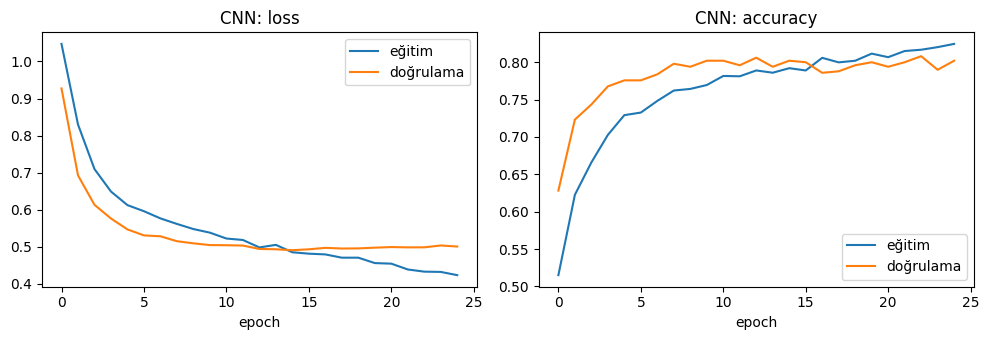

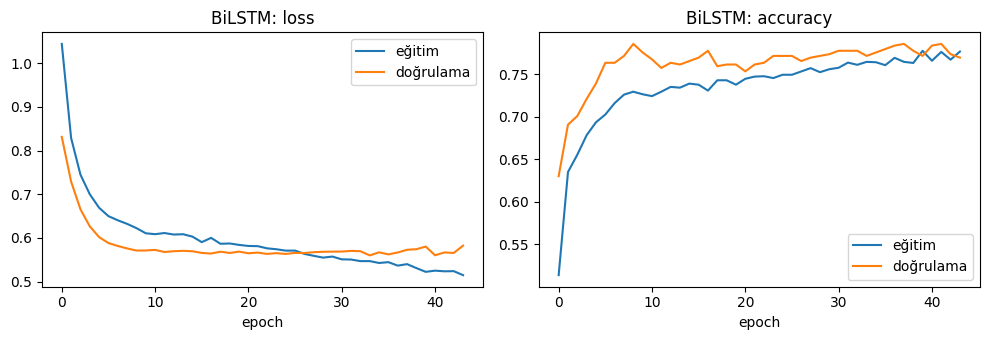

In [15]:
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import pad_sequences
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv")
siniflar = ["Arapça", "Farsça", "Türkçe"]
s2i = {s: i for i, s in enumerate(siniflar)}
mark = lambda s: "^" + s + "$"
harfler = sorted(set("".join(train["kelime"].map(mark))))
c2i = {c: i + 2 for i, c in enumerate(harfler)}      # 0 = dolgu, 1 = bilinmeyen harf
MAXLEN, V = 11, len(c2i) + 2

def encode(df):
    X = [[c2i.get(c, 1) for c in mark(w)] for w in df["kelime"]]
    return pad_sequences(X, maxlen=MAXLEN, padding="post"), df["sinif"].map(s2i).values

Xtr, ytr = encode(train); Xva, yva = encode(val)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=ytr)))

def build(tip):
    inp = keras.Input(shape=(MAXLEN,))
    if tip == "CNN":
        x = layers.Embedding(V, 32)(inp)
        x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
        x = layers.GlobalMaxPooling1D()(x)
    else:
        x = layers.Embedding(V, 32, mask_zero=True)(inp)
        x = layers.Bidirectional(layers.LSTM(32))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(3, activation="softmax")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

sonuc, gecmis = [], {}
for tip in ["CNN", "BiLSTM"]:
    for seed in [1, 2, 3]:
        keras.utils.set_random_seed(seed)
        m = build(tip)
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                           restore_best_weights=True)
        h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=32,
                  class_weight=cw, callbacks=[es], verbose=0)
        p = m.predict(Xva, verbose=0).argmax(1)
        sonuc.append(dict(model=tip, seed=seed, parametre=m.count_params(),
                          en_iyi_epoch=int(np.argmin(h.history["val_loss"])) + 1,
                          acc=accuracy_score(yva, p),
                          macro_f1=f1_score(yva, p, average="macro")))
        if seed == 1:
            gecmis[tip] = h.history

r = pd.DataFrame(sonuc)
print(r.round(3).to_string(index=False))
print("\nÜç seed ortalaması ± standart sapma:")
print(r.groupby("model")[["acc", "macro_f1"]].agg(["mean", "std"]).round(3))

for tip, hist in gecmis.items():
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(hist["loss"], label="eğitim"); ax[0].plot(hist["val_loss"], label="doğrulama")
    ax[0].set_title(f"{tip}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["accuracy"], label="eğitim"); ax[1].plot(hist["val_accuracy"], label="doğrulama")
    ax[1].set_title(f"{tip}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"egitim_{tip}.png", dpi=200); plt.show()

### Epoch özeti (aşırı/yetersiz uyum kontrolü)

In [16]:
for tip, h in gecmis.items():
    n = len(h["loss"]); en = int(np.argmin(h["val_loss"]))
    print(f"\n{tip} (seed 1): toplam {n} epoch, en iyi epoch {en+1}")
    for ad, i in [("en iyi epoch", en), ("son epoch", n-1)]:
        print(f"  {ad:13} | eğitim loss {h['loss'][i]:.3f} acc {h['accuracy'][i]:.3f} "
              f"| doğrulama loss {h['val_loss'][i]:.3f} acc {h['val_accuracy'][i]:.3f}")


CNN (seed 1): toplam 25 epoch, en iyi epoch 15
  en iyi epoch  | eğitim loss 0.485 acc 0.792 | doğrulama loss 0.491 acc 0.802
  son epoch     | eğitim loss 0.424 acc 0.825 | doğrulama loss 0.501 acc 0.802

BiLSTM (seed 1): toplam 44 epoch, en iyi epoch 34
  en iyi epoch  | eğitim loss 0.547 acc 0.765 | doğrulama loss 0.560 acc 0.772
  son epoch     | eğitim loss 0.515 acc 0.777 | doğrulama loss 0.582 acc 0.770


## E. Nihai test değerlendirmesi ve ek analizler
Test kümesi burada, model ve ayarlar sabitlendikten sonra **bir kez** kullanılır. Etiket denetimi betimleyicidir. Öğrenme eğrileri (son iki hücre) test kümesini kullanmaz.

### Veri yükleme ve sabitler

In [17]:
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import pad_sequences
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import binomtest
import matplotlib.pyplot as plt

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv"); test = pd.read_csv("test.csv")
print("Boyutlar -> train:", len(train), "| val:", len(val), "| test:", len(test))
print("Test sınıf oranları:", test["sinif"].value_counts(normalize=True).round(3).to_dict())

SINIF = ["Arapça", "Farsça", "Türkçe"]
mark = lambda s: "^" + s + "$"
y_tr, y_va, y_te = train["sinif"].values, val["sinif"].values, test["sinif"].values

# Doğrulama sonuçları (not defterindeki çıktılar) -> yeniden üretilebilirlik kontrolü
VAL_REF = {"LR": (0.808, 0.795), "SVM": (0.804, 0.785)}

preds, val_acc = {}, {}

Boyutlar -> train: 2308 | val: 495 | test: 495
Test sınıf oranları: {'Arapça': 0.444, 'Türkçe': 0.329, 'Farsça': 0.226}


### M0 (çoğunluk sınıfı)

In [18]:
# ---------- M0 ----------
m0 = pd.Series(y_tr).value_counts().idxmax()
preds["M0"] = np.array([m0] * len(test))

### LR ve SVM

In [19]:
# ---------- LR ve SVM ----------
def sk_model(kind):
    clf = (LogisticRegression(C=1, class_weight="balanced", max_iter=2000, random_state=42)
           if kind == "LR" else LinearSVC(C=0.3, class_weight="balanced", random_state=42))
    return make_pipeline(TfidfVectorizer(analyzer="char", ngram_range=(1, 3), sublinear_tf=True), clf)

Xtr_s = train["kelime"].map(mark); Xva_s = val["kelime"].map(mark); Xte_s = test["kelime"].map(mark)
for kind in ["LR", "SVM"]:
    pipe = sk_model(kind).fit(Xtr_s, y_tr)            # sadece train ile eğitilir
    pv = pipe.predict(Xva_s)
    a, f = accuracy_score(y_va, pv), f1_score(y_va, pv, average="macro")
    ra, rf = VAL_REF[kind]
    durum = "OK" if abs(a - ra) < 0.003 and abs(f - rf) < 0.003 else "UYARI: doğrulama sonucu farklı, dosyaları kontrol et"
    print(f"[kontrol] {kind} doğrulama acc={a:.3f} F1={f:.3f} (not defteri: {ra}/{rf}) -> {durum}")
    preds[kind] = pipe.predict(Xte_s)
    if kind == "LR":
        lr_pipe = pipe

[kontrol] LR doğrulama acc=0.808 F1=0.795 (not defteri: 0.808/0.795) -> OK
[kontrol] SVM doğrulama acc=0.804 F1=0.785 (not defteri: 0.804/0.785) -> OK


### CNN (3 seed)

In [20]:
# ---------- CNN (3 seed) ----------
harfler = sorted(set("".join(train["kelime"].map(mark))))
c2i = {c: i + 2 for i, c in enumerate(harfler)}       # 0 = dolgu, 1 = bilinmeyen harf
MAXLEN, V = 11, len(c2i) + 2
s2i = {s: i for i, s in enumerate(SINIF)}

def encode(df):
    X = [[c2i.get(c, 1) for c in mark(w)] for w in df["kelime"]]
    return pad_sequences(X, maxlen=MAXLEN, padding="post"), df["sinif"].map(s2i).values

Xtr, ytr_i = encode(train); Xva, yva_i = encode(val); Xte, yte_i = encode(test)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=ytr_i)))

def build_cnn():
    inp = keras.Input(shape=(MAXLEN,))
    x = layers.Embedding(V, 32)(inp)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(3, activation="softmax")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

CNN_VAL_REF = {1: 0.802, 2: 0.814, 3: 0.796}
for seed in [1, 2, 3]:
    keras.utils.set_random_seed(seed)
    m = build_cnn()
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    m.fit(Xtr, ytr_i, validation_data=(Xva, yva_i), epochs=100, batch_size=32,
          class_weight=cw, callbacks=[es], verbose=0)
    va = accuracy_score(yva_i, m.predict(Xva, verbose=0).argmax(1))
    print(f"[kontrol] CNN seed{seed} doğrulama acc={va:.3f} (not defteri: {CNN_VAL_REF[seed]}; "
          f"GPU nedeniyle küçük sapma beklenir)")
    preds[f"CNN_s{seed}"] = np.array(SINIF)[m.predict(Xte, verbose=0).argmax(1)]

[kontrol] CNN seed1 doğrulama acc=0.802 (not defteri: 0.802; GPU nedeniyle küçük sapma beklenir)
[kontrol] CNN seed2 doğrulama acc=0.814 (not defteri: 0.814; GPU nedeniyle küçük sapma beklenir)
[kontrol] CNN seed3 doğrulama acc=0.796 (not defteri: 0.796; GPU nedeniyle küçük sapma beklenir)


### Metrikler ve bootstrap güven aralığı

In [21]:
# ---------- Metrikler + bootstrap %95 GA (aynı yeniden örneklemeler tüm modeller için) ----------
B = 2000
rng = np.random.default_rng(42)
idx = rng.integers(0, len(test), size=(B, len(test)))

def boot_ci(pred):
    a = np.empty(B); f = np.empty(B)
    for b, ix in enumerate(idx):
        a[b] = accuracy_score(y_te[ix], pred[ix]); f[b] = f1_score(y_te[ix], pred[ix], average="macro")
    return np.percentile(a, [2.5, 97.5]), np.percentile(f, [2.5, 97.5])

rows = []
for ad, p in preds.items():
    (a_lo, a_hi), (f_lo, f_hi) = boot_ci(p)
    rows.append(dict(model=ad, acc=accuracy_score(y_te, p), acc_GA=f"[{a_lo:.3f}, {a_hi:.3f}]",
                     macro_F1=f1_score(y_te, p, average="macro"), F1_GA=f"[{f_lo:.3f}, {f_hi:.3f}]"))
tablo = pd.DataFrame(rows)
print("\n=== TEST SONUÇLARI (bootstrap %95 GA, B=2000) ===")
print(tablo.round(3).to_string(index=False))
cnn = tablo[tablo.model.str.startswith("CNN")]
print(f"\nCNN 3 seed ortalaması: acc={cnn.acc.mean():.3f} ± {cnn.acc.std():.3f} | "
      f"macro-F1={cnn.macro_F1.mean():.3f} ± {cnn.macro_F1.std():.3f}")
tablo.to_csv("test_sonuclari.csv", index=False)


=== TEST SONUÇLARI (bootstrap %95 GA, B=2000) ===
 model   acc         acc_GA  macro_F1          F1_GA
    M0 0.444 [0.400, 0.491]     0.205 [0.190, 0.220]
    LR 0.802 [0.766, 0.836]     0.787 [0.749, 0.825]
   SVM 0.816 [0.782, 0.848]     0.797 [0.761, 0.835]
CNN_s1 0.776 [0.739, 0.814]     0.760 [0.721, 0.799]
CNN_s2 0.798 [0.764, 0.832]     0.781 [0.744, 0.818]
CNN_s3 0.784 [0.747, 0.818]     0.769 [0.729, 0.805]

CNN 3 seed ortalaması: acc=0.786 ± 0.011 | macro-F1=0.770 ± 0.010


### McNemar (LR vs CNN seed 1)

In [22]:
# ---------- McNemar (kesin/binom): LR vs CNN seed1 ----------
d_lr = preds["LR"] == y_te; d_cnn = preds["CNN_s1"] == y_te
b01 = int((d_lr & ~d_cnn).sum()); c01 = int((~d_lr & d_cnn).sum())
p_mc = binomtest(min(b01, c01), b01 + c01, 0.5).pvalue if (b01 + c01) > 0 else 1.0
print(f"\nMcNemar (LR vs CNN seed1): yalnız LR doğru={b01}, yalnız CNN doğru={c01}, p={p_mc:.3f}")


McNemar (LR vs CNN seed1): yalnız LR doğru=37, yalnız CNN doğru=24, p=0.124


### Karışıklık matrisleri

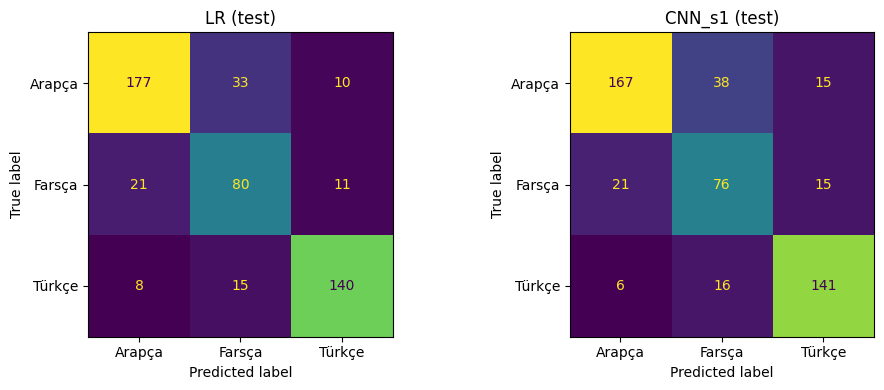

In [23]:
# ---------- Karışıklık matrisleri ----------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, ad in zip(ax, ["LR", "CNN_s1"]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, preds[ad], labels=SINIF),
                           display_labels=SINIF).plot(ax=a_, colorbar=False, values_format="d")
    a_.set_title(f"{ad} (test)")
plt.tight_layout(); plt.savefig("test_karisiklik.png", dpi=200); plt.show()

### Hata analizi (LR)

In [24]:
# ---------- Hata analizi (LR) - yalnızca betimleyici ----------
print("\n=== LR sınıf bazlı rapor (test) ===")
print(classification_report(y_te, preds["LR"], labels=SINIF, digits=3))

t = test.copy(); t["tahmin"] = preds["LR"]; t["dogru"] = t["tahmin"] == t["sinif"]
yanlis = t[~t["dogru"]]
ar_fa = ((yanlis.sinif == "Arapça") & (yanlis.tahmin == "Farsça")) | ((yanlis.sinif == "Farsça") & (yanlis.tahmin == "Arapça"))
print(f"LR toplam hata: {len(yanlis)} | Arapça<->Farsça karışıklığı: {int(ar_fa.sum())} ({ar_fa.mean():.1%})")

print("\nÖzel isim / diğer doğruluk:")
print(t.groupby("ozel_isim")["dogru"].agg(["mean", "count"]).round(3))

tr = t[t.sinif == "Türkçe"].copy()
tr["son_ق_ك"] = tr["kelime"].str[-1].isin(["ق", "ك"])
print("\nTürkçe recall (son harf ق/ك olanlar ve olmayanlar):")
print(tr.groupby("son_ق_ك")["dogru"].agg(["mean", "count"]).round(3))

for (g, p_), d in yanlis.groupby(["sinif", "tahmin"]):
    print(f"\ngerçek {g} -> tahmin {p_} ({len(d)}):", list(d["kelime"].head(12)))


=== LR sınıf bazlı rapor (test) ===
              precision    recall  f1-score   support

      Arapça      0.859     0.805     0.831       220
      Farsça      0.625     0.714     0.667       112
      Türkçe      0.870     0.859     0.864       163

    accuracy                          0.802       495
   macro avg      0.785     0.793     0.787       495
weighted avg      0.810     0.802     0.805       495

LR toplam hata: 98 | Arapça<->Farsça karışıklığı: 54 (55.1%)

Özel isim / diğer doğruluk:
            mean  count
ozel_isim              
False      0.802    459
True       0.806     36

Türkçe recall (son harf ق/ك olanlar ve olmayanlar):
          mean  count
son_ق_ك              
False    0.761     88
True     0.973     75

gerçek Arapça -> tahmin Farsça (33): ['هندبا', 'غیور', 'دماغ', 'لبن', 'درس', 'دسام', 'سطوت', 'وزنه', 'لوز', 'خیال', 'سراب', 'جندل']

gerçek Arapça -> tahmin Türkçe (10): ['قلق', 'قدیم', 'قاتل', 'صاروج', 'طاق', 'سكوت', 'شوك', 'طوبی', 'طباق', 'انبیق']

ger

### Etiket denetimi (betimleyici; veri ve model değiştirilmez)

In [25]:
# ============================================================
# ETİKET DENETİMİ (betimleyici analiz; veri, etiket veya model DEĞİŞTİRİLMEYECEK)
# Önkoşul: Test not defterinin 8. hücresi (hata analizi) aynı oturumda çalıştırılmış olmalı,
#          yani `yanlis` tablosu (LR'nin test hataları; sütunlar: kelime, sinif, tahmin) bellekte.
# Amaç: "Arapça etiketli ama modelin Farsça dediği" kelimelerden rastgele 10 tanesinin
#       Wiktionary'deki köken (Etymology) bölümünü okumak.
# ============================================================
import re, time, requests

S = requests.Session()
S.headers.update({"User-Agent": "OsmanliKokenProjesi/1.0 (ogrenci ders projesi)"})
API = "https://en.wiktionary.org/w/api.php"

def sayfa_metni(kelime):
    r = S.get(API, params={"action": "query", "prop": "revisions", "rvprop": "content",
                           "rvslots": "main", "titles": kelime,
                           "format": "json", "formatversion": 2}, timeout=60)
    r.raise_for_status()
    sayfa = r.json()["query"]["pages"][0]
    if sayfa.get("missing"):
        return None
    return sayfa["revisions"][0]["slots"]["main"]["content"]

def etimoloji_ayikla(wikitext, uzunluk=450):
    """Sayfadaki '==Ottoman Turkish==' bölümünün Etymology alt bölümünü döndürür."""
    m = re.search(r"(?ms)^==\s*Ottoman Turkish\s*==\s*\n(.*?)(?=^==[^=]|\Z)", wikitext)
    if not m:
        return "(Osmanlıca bölümü bulunamadı)"
    e = re.search(r"(?ms)^===\s*Etymology[^=\n]*===\s*\n(.*?)(?=^===|\Z)", m.group(1))
    if not e:
        return "(Etymology alt bölümü bulunamadı)"
    return e.group(1).strip()[:uzunluk]

grup = yanlis[(yanlis.sinif == "Arapça") & (yanlis.tahmin == "Farsça")]
ornek = grup.sample(10, random_state=42)          # sabit tohum: kelimeleri biz seçmiyoruz
print(f"Arapça->Farsça hata sayısı: {len(grup)} | incelenen rastgele örnek: {len(ornek)}\n")

for k in ornek["kelime"]:
    print("=" * 70)
    print("KELİME:", k, "| etiket: Arapça | model: Farsça")
    try:
        metin = sayfa_metni(k)
        print("KÖKEN :", "(sayfa bulunamadı: hareke/ZWNJ farkı olabilir)" if metin is None
              else etimoloji_ayikla(metin))
    except Exception as ex:
        print("HATA  :", ex)
    time.sleep(1.0)

Arapça->Farsça hata sayısı: 33 | incelenen rastgele örnek: 10

KELİME: نرجس | etiket: Arapça | model: Farsça
KÖKEN : {{bor+|ota|ar|نَرْجِس}}, from {{der|ota|pal|sc=Phlv|tr=nlgs|ts=nargis}}, from {{der|ota|grc|νάρκισσος}}.
KELİME: تابوت | etiket: Arapça | model: Farsça
KÖKEN : {{bor+|ota|ar|تَابُوت}}, from {{der|ota|syc|ܬܝܒܘܬܐ|tr=<span style="margin-right:1.5px">tēḇūṯā</span>}}, ultimately from a merger of {{der|ota|egy|-}} {{egy-h|DbA-t:pr}} {{m|egy|ḏbꜣt||sarcophagus, coffin}} and {{egy-h|T-b-O39}} {{m|egy|ṯb||chest, box}}.
KELİME: تنین | etiket: Arapça | model: Farsça
KÖKEN : {{ety|ota|:bor|ar:تِنِّين<t:sea serpent, dragon>|text=+|tree=1}}
KELİME: شریك | etiket: Arapça | model: Farsça
KÖKEN : {{ety|ota|:bor|ar:شَرِيك<ety:der<ar:شَرِكَ>>|tree=1}}
{{bor+|ota|ar|شَرِيك||partner, associate}}, a derivation from the active participle of the verb {{m|ar|شَرِكَ||to share}}. {{root|ota|ar|ش ر ك}}
KELİME: لوز | etiket: Arapça | model: Farsça
KÖKEN : {{ety|ota|:bor|ar:لَوْز<t:almond>|text=+|tree

### Öğrenme eğrisi: LR (yalnızca train/val)

 oran    n  train_acc  val_acc  val_acc_std  val_f1
  0.1  230      0.992    0.715        0.020   0.692
  0.2  461      0.963    0.752        0.011   0.733
  0.4  923      0.935    0.777        0.004   0.759
  0.6 1384      0.917    0.792        0.004   0.777
  0.8 1846      0.912    0.803        0.013   0.788
  1.0 2308      0.901    0.808        0.000   0.795


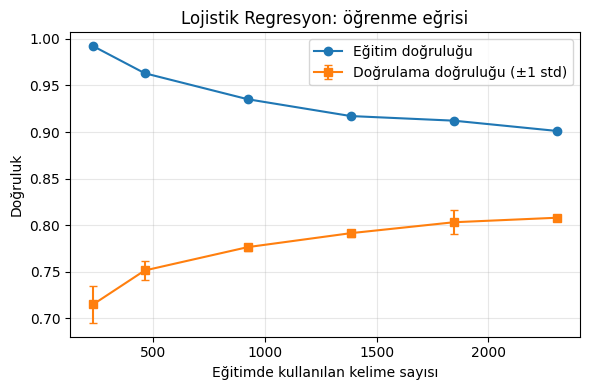

In [26]:
# ============================================================
# ÖĞRENME EĞRİSİ (LR) - yalnızca train ve val kullanılır, TEST'E DOKUNULMAZ
# Soru: Daha fazla eğitim verisi doğrulama başarısını artırır mı?
# Gerekli dosyalar: train.csv, val.csv
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv")
mark = lambda s: "^" + s + "$"
Xtr_all = train["kelime"].map(mark).values; ytr_all = train["sinif"].values
Xva = val["kelime"].map(mark).values;       yva = val["sinif"].values

def model():
    return make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=(1, 3), sublinear_tf=True),
        LogisticRegression(C=1, class_weight="balanced", max_iter=2000, random_state=42))

FRAK = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
TEKRAR = 5                       # her oran için 5 farklı rastgele (stratified) alt küme
rows = []
for f in FRAK:
    for r in range(1 if f == 1.0 else TEKRAR):
        if f == 1.0:
            Xs, ys = Xtr_all, ytr_all
        else:
            Xs, _, ys, _ = train_test_split(Xtr_all, ytr_all, train_size=f,
                                            stratify=ytr_all, random_state=r)
        m = model().fit(Xs, ys)
        rows.append(dict(oran=f, n=len(Xs),
                         train_acc=accuracy_score(ys, m.predict(Xs)),
                         val_acc=accuracy_score(yva, m.predict(Xva)),
                         val_f1=f1_score(yva, m.predict(Xva), average="macro")))
res = pd.DataFrame(rows)
ozet = res.groupby(["oran", "n"]).agg(
    train_acc=("train_acc", "mean"),
    val_acc=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
    val_f1=("val_f1", "mean")).reset_index().fillna(0)
print(ozet.round(3).to_string(index=False))
ozet.to_csv("ogrenme_egrisi.csv", index=False)

plt.figure(figsize=(6, 4))
plt.plot(ozet["n"], ozet["train_acc"], "o-", label="Eğitim doğruluğu")
plt.errorbar(ozet["n"], ozet["val_acc"], yerr=ozet["val_acc_std"], fmt="s-", capsize=3,
             label="Doğrulama doğruluğu (±1 std)")
plt.xlabel("Eğitimde kullanılan kelime sayısı"); plt.ylabel("Doğruluk")
plt.title("Lojistik Regresyon: öğrenme eğrisi"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("ogrenme_egrisi.png", dpi=200); plt.show()

### Öğrenme eğrisi: CNN ve LR karşılaştırması (yalnızca train/val)

oran=0.1 n=230 tekrar=0: val_acc=0.669
oran=0.1 n=230 tekrar=1: val_acc=0.695
oran=0.1 n=230 tekrar=2: val_acc=0.685
oran=0.2 n=461 tekrar=0: val_acc=0.735
oran=0.2 n=461 tekrar=1: val_acc=0.754
oran=0.2 n=461 tekrar=2: val_acc=0.723
oran=0.4 n=923 tekrar=0: val_acc=0.758
oran=0.4 n=923 tekrar=1: val_acc=0.766
oran=0.4 n=923 tekrar=2: val_acc=0.786
oran=0.6 n=1384 tekrar=0: val_acc=0.758
oran=0.6 n=1384 tekrar=1: val_acc=0.796
oran=0.6 n=1384 tekrar=2: val_acc=0.788
oran=0.8 n=1846 tekrar=0: val_acc=0.790
oran=0.8 n=1846 tekrar=1: val_acc=0.782
oran=0.8 n=1846 tekrar=2: val_acc=0.804
oran=1.0 n=2308 tekrar=0: val_acc=0.802
oran=1.0 n=2308 tekrar=1: val_acc=0.814
oran=1.0 n=2308 tekrar=2: val_acc=0.796

  oran    n  train_acc  val_acc  val_acc_std  val_f1
  0.1  230      0.878    0.683        0.013   0.663
  0.2  461      0.860    0.737        0.015   0.719
  0.4  923      0.856    0.770        0.015   0.752
  0.6 1384      0.840    0.780        0.020   0.763
  0.8 1846      0.855    0.

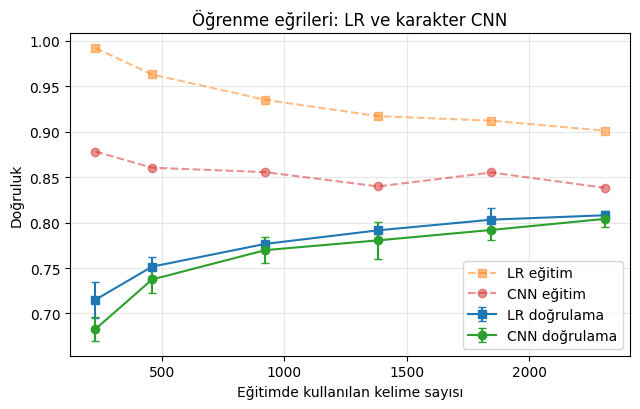

In [27]:
# ============================================================
# ÖĞRENME EĞRİSİ (karakter CNN) - yalnızca train ve val kullanılır, TEST'E DOKUNULMAZ
# Gerekli dosyalar: train.csv, val.csv  (LR eğrisi ogrenme_egrisi.csv varsa grafiğe eklenir)
# Mimari ve ayarlar final CNN ile aynıdır; her oran için 3 farklı alt küme + seed.
# ============================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv")
SINIF = ["Arapça", "Farsça", "Türkçe"]; s2i = {s: i for i, s in enumerate(SINIF)}
mark = lambda s: "^" + s + "$"

# Harf sözlüğü tam eğitim kümesinden (yalnızca harf envanteri, etiket bilgisi yok)
harfler = sorted(set("".join(train["kelime"].map(mark))))
c2i = {c: i + 2 for i, c in enumerate(harfler)}
MAXLEN, V = 11, len(c2i) + 2

def encode(df):
    X = [[c2i.get(c, 1) for c in mark(w)] for w in df["kelime"]]
    return pad_sequences(X, maxlen=MAXLEN, padding="post"), df["sinif"].map(s2i).values

Xtr_all, ytr_all = encode(train); Xva, yva = encode(val)

def build_cnn():
    inp = keras.Input(shape=(MAXLEN,))
    x = layers.Embedding(V, 32)(inp)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(3, activation="softmax")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

FRAK = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
TEKRAR = 3
rows = []
for f in FRAK:
    for r in range(TEKRAR):
        if f == 1.0:
            Xs, ys = Xtr_all, ytr_all                      # CNN rastgele olduğu için seed yine değişir
        else:
            Xs, _, ys, _ = train_test_split(Xtr_all, ytr_all, train_size=f,
                                            stratify=ytr_all, random_state=r)
        keras.utils.set_random_seed(r + 1)
        m = build_cnn()
        cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=ys)))
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
        m.fit(Xs, ys, validation_data=(Xva, yva), epochs=100, batch_size=32,
              class_weight=cw, callbacks=[es], verbose=0)
        p_tr = m.predict(Xs, verbose=0).argmax(1)           # dropout kapalı, gerçek eğitim doğruluğu
        p_va = m.predict(Xva, verbose=0).argmax(1)
        rows.append(dict(oran=f, n=len(Xs), train_acc=accuracy_score(ys, p_tr),
                         val_acc=accuracy_score(yva, p_va),
                         val_f1=f1_score(yva, p_va, average="macro")))
        print(f"oran={f:.1f} n={len(Xs)} tekrar={r}: val_acc={rows[-1]['val_acc']:.3f}")

res = pd.DataFrame(rows)
ozet = res.groupby(["oran", "n"]).agg(
    train_acc=("train_acc", "mean"),
    val_acc=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
    val_f1=("val_f1", "mean")).reset_index().fillna(0)
print("\n", ozet.round(3).to_string(index=False))
ozet.to_csv("ogrenme_egrisi_cnn.csv", index=False)

plt.figure(figsize=(6.5, 4.2))
if os.path.exists("ogrenme_egrisi.csv"):
    lr = pd.read_csv("ogrenme_egrisi.csv")
    plt.errorbar(lr["n"], lr["val_acc"], yerr=lr["val_acc_std"], fmt="s-", capsize=3, label="LR doğrulama")
    plt.plot(lr["n"], lr["train_acc"], "s--", alpha=.5, label="LR eğitim")
plt.errorbar(ozet["n"], ozet["val_acc"], yerr=ozet["val_acc_std"], fmt="o-", capsize=3, label="CNN doğrulama")
plt.plot(ozet["n"], ozet["train_acc"], "o--", alpha=.5, label="CNN eğitim")
plt.xlabel("Eğitimde kullanılan kelime sayısı"); plt.ylabel("Doğruluk")
plt.title("Öğrenme eğrileri: LR ve karakter CNN"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("ogrenme_egrisi_karsilastirma.png", dpi=200); plt.show()